In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import ast

# Display all rows
pd.set_option('display.max_rows', None)

# Display all columns
pd.set_option('display.max_columns', None)

# Display full column width (prclickstream truncation of long strings/text)
pd.set_option('display.max_colwidth', None)

# Ensure the output width accommodates all columns in a console
pd.set_option('display.width', None)

In [38]:
data_path = Path("../data/raw")

In [39]:
transactions = pd.read_csv(data_path/'transactions.csv')


# Transactions focus

In [40]:
transactions.head()

,created_at,customer_id,booking_id,session_id,product_metadata,payment_method,payment_status,promo_amount,promo_code,shipment_fee,shipment_date_limit,shipment_location_lat,shipment_location_long,total_amount
0,2018-07-29T15:22:01.458193Z,5868,186e2bee-0637-4710-8981-50c2d737bc42,3abaa6ce-e320-4e51-9469-d9f3fa328e86,"[{'product_id': 54728, 'quantity': 1, 'item_price': 191247}]",Debit Card,Success,1415,WEEKENDSERU,10000,2018-08-03T05:07:24.812676Z,-8.227893,111.969107,199832
1,2018-07-30T12:40:22.365620Z,4774,caadb57b-e808-4f94-9e96-8a7d4c9898db,2ee5ead1-f13e-4759-92df-7ff48475e970,"[{'product_id': 16193, 'quantity': 1, 'item_price': 145526}]",Credit Card,Success,0,NaN,10000,2018-08-03T01:29:03.415705Z,3.013470,107.802514,155526
2,2018-09-15T11:51:17.365620Z,4774,6000fffb-9c1a-4f4a-9296-bc8f6b622b50,93325fb6-eb00-4268-bb0e-6471795a0ad0,"[{'product_id': 53686, 'quantity': 4, 'item_price': 135174}]",OVO,Success,0,NaN,10000,2018-09-18T08:41:49.422380Z,-2.579428,115.743885,550696
3,2018-11-01T11:23:48.365620Z,4774,f5e530a7-4350-4cd1-a3bc-525b5037bcab,bcad5a61-1b67-448d-8ff4-781d67bc56e4,"[{'product_id': 20228, 'quantity': 1, 'item_price': 271012}]",Credit Card,Success,0,NaN,0,2018-11-05T17:42:27.954235Z,-3.602334,120.363824,271012
4,2018-12-18T11:20:30.365620Z,4774,0efc0594-dbbf-4f9a-b0b0-a488cfddf8a2,df1042ab-13e6-4072-b9d2-64a81974c51a,"[{'product_id': 55220, 'quantity': 1, 'item_price': 198753}]",Credit Card,Success,0,NaN,0,2018-12-23T17:24:07.361785Z,-3.602334,120.363824,198753


In [41]:
transactions.isna().sum()

created_at                     0
customer_id                    0
booking_id                     0
session_id                     0
product_metadata               0
payment_method                 0
payment_status                 0
promo_amount                   0
promo_code                526048
shipment_fee                   0
shipment_date_limit            0
shipment_location_lat          0
shipment_location_long         0
total_amount                   0
dtype: int64

In [42]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 852584 entries, 0 to 852583
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   created_at              852584 non-null  object 
 1   customer_id             852584 non-null  int64  
 2   booking_id              852584 non-null  object 
 3   session_id              852584 non-null  object 
 4   product_metadata        852584 non-null  object 
 5   payment_method          852584 non-null  object 
 6   payment_status          852584 non-null  object 
 7   promo_amount            852584 non-null  int64  
 8   promo_code              326536 non-null  object 
 9   shipment_fee            852584 non-null  int64  
 10  shipment_date_limit     852584 non-null  object 
 11  shipment_location_lat   852584 non-null  float64
 12  shipment_location_long  852584 non-null  float64
 13  total_amount            852584 non-null  int64  
dtypes: float64(2), int64

In [43]:
transactions['created_at'] = pd.to_datetime(transactions['created_at'])
transactions['shipment_date_limit'] = pd.to_datetime(transactions['shipment_date_limit'])

In [44]:
cat_cols = ['payment_method', 'payment_status', 'promo_code']
for col in cat_cols:
    transactions[col] = transactions[col].astype('category')

In [45]:
# 1. Fill NaN in promo_code with 'NO_PROMO'
if 'NO_PROMO' not in transactions['promo_code'].dtype.categories if hasattr(transactions['promo_code'], 'cat') else True:
    if hasattr(transactions['promo_code'], 'cat'):
        transactions['promo_code'] = transactions['promo_code'].cat.add_categories(['NO_PROMO'])
    
transactions['promo_code'] = transactions['promo_code'].fillna('NO_PROMO')

# 3. Feature Engineering: Create a Boolean flag for "Was a discount used?"
transactions['is_discounted'] = transactions['promo_amount'] > 0

# 4. Feature Engineering: Calculate Discount Percentage
# This shows how aggressive the discount was relative to the total price
transactions['discount_pct'] = (transactions['promo_amount'] / transactions['total_amount']).fillna(0)

In [46]:
# 1. Convert string representation to actual list
def safe_literal_eval(x):
    try:
        return ast.literal_eval(x)
    except (ValueError, SyntaxError):
        return []  # or None, depending on your needs

transactions['product_metadata'] = transactions['product_metadata'].apply(safe_literal_eval)

# 2. Explode the list so each item gets its own row
# We overwrite transactions here to save memory
transactions = transactions.explode('product_metadata')
transactions = transactions.reset_index(drop=True)


# 3. Extract the dictionary keys into separate columns and concatenate
# Using pd.DataFrame(....tolist()) is much faster than .apply(pd.Series)
meta_df = pd.DataFrame(transactions['product_metadata'].tolist(), index=transactions.index)

# Join the new columns back and drop the original nested column
transactions = pd.concat([transactions.drop('product_metadata', axis=1), meta_df], axis=1)

In [47]:
transactions.head()

,created_at,customer_id,booking_id,session_id,payment_method,payment_status,promo_amount,promo_code,shipment_fee,shipment_date_limit,shipment_location_lat,shipment_location_long,total_amount,is_discounted,discount_pct,product_id,quantity,item_price
0,2018-07-29 15:22:01.458193+00:00,5868,186e2bee-0637-4710-8981-50c2d737bc42,3abaa6ce-e320-4e51-9469-d9f3fa328e86,Debit Card,Success,1415,WEEKENDSERU,10000,2018-08-03 05:07:24.812676+00:00,-8.227893,111.969107,199832,True,0.007081,54728,1,191247
1,2018-07-30 12:40:22.365620+00:00,4774,caadb57b-e808-4f94-9e96-8a7d4c9898db,2ee5ead1-f13e-4759-92df-7ff48475e970,Credit Card,Success,0,NO_PROMO,10000,2018-08-03 01:29:03.415705+00:00,3.013470,107.802514,155526,False,0.000000,16193,1,145526
2,2018-09-15 11:51:17.365620+00:00,4774,6000fffb-9c1a-4f4a-9296-bc8f6b622b50,93325fb6-eb00-4268-bb0e-6471795a0ad0,OVO,Success,0,NO_PROMO,10000,2018-09-18 08:41:49.422380+00:00,-2.579428,115.743885,550696,False,0.000000,53686,4,135174
3,2018-11-01 11:23:48.365620+00:00,4774,f5e530a7-4350-4cd1-a3bc-525b5037bcab,bcad5a61-1b67-448d-8ff4-781d67bc56e4,Credit Card,Success,0,NO_PROMO,0,2018-11-05 17:42:27.954235+00:00,-3.602334,120.363824,271012,False,0.000000,20228,1,271012
4,2018-12-18 11:20:30.365620+00:00,4774,0efc0594-dbbf-4f9a-b0b0-a488cfddf8a2,df1042ab-13e6-4072-b9d2-64a81974c51a,Credit Card,Success,0,NO_PROMO,0,2018-12-23 17:24:07.361785+00:00,-3.602334,120.363824,198753,False,0.000000,55220,1,198753


In [48]:
transactions.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254585 entries, 0 to 1254584
Data columns (total 18 columns):
 #   Column                  Non-Null Count    Dtype              
---  ------                  --------------    -----              
 0   created_at              1254585 non-null  datetime64[ns, UTC]
 1   customer_id             1254585 non-null  int64              
 2   booking_id              1254585 non-null  object             
 3   session_id              1254585 non-null  object             
 4   payment_method          1254585 non-null  category           
 5   payment_status          1254585 non-null  category           
 6   promo_amount            1254585 non-null  int64              
 7   promo_code              1254585 non-null  category           
 8   shipment_fee            1254585 non-null  int64              
 9   shipment_date_limit     1254585 non-null  datetime64[ns, UTC]
 10  shipment_location_lat   1254585 non-null  float64            
 11  shipment_lo

In [49]:
transactions['created_at'].max()

Timestamp('2022-07-31 23:59:45.821469+0000', tz='UTC')

In [50]:
# Downcast to save more memory
# customer_id and product_id fit in int32; quantity fits in int8
transactions['customer_id'] = transactions['customer_id'].astype('int32')
transactions['product_id'] = transactions['product_id'].astype('int32')
transactions['quantity'] = transactions['quantity'].astype('int16')
transactions['shipment_location_lat'] = transactions['shipment_location_lat'].astype('float32')
transactions['shipment_location_long'] = transactions['shipment_location_long'].astype('float32')

In [51]:
transactions.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254585 entries, 0 to 1254584
Data columns (total 18 columns):
 #   Column                  Non-Null Count    Dtype              
---  ------                  --------------    -----              
 0   created_at              1254585 non-null  datetime64[ns, UTC]
 1   customer_id             1254585 non-null  int32              
 2   booking_id              1254585 non-null  object             
 3   session_id              1254585 non-null  object             
 4   payment_method          1254585 non-null  category           
 5   payment_status          1254585 non-null  category           
 6   promo_amount            1254585 non-null  int64              
 7   promo_code              1254585 non-null  category           
 8   shipment_fee            1254585 non-null  int64              
 9   shipment_date_limit     1254585 non-null  datetime64[ns, UTC]
 10  shipment_location_lat   1254585 non-null  float32            
 11  shipment_lo

In [52]:
# Verify that total_amount equals sum(line_total) + shipment_fee - promo_amount per booking
line_totals = transactions.groupby('booking_id').apply(
    lambda g: (g['quantity'] * g['item_price']).sum() + g['shipment_fee'].iloc[0] - g['promo_amount'].iloc[0]
)
mismatches = (line_totals != transactions.groupby('booking_id')['total_amount'].first()).sum()
print(f"Orders with inconsistent total: {mismatches}")

C:\Users\hayao\AppData\Local\Temp\ipykernel_25520\2475896375.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  line_totals = transactions.groupby('booking_id').apply(


Orders with inconsistent total: 0


In [53]:
# Missing values
print("Missing values per column:\n", transactions.isnull().sum())

# Duplicate booking_id? (should be unique after explosion)
duplicate_booking = transactions['booking_id'].duplicated().any()
print(f"Duplicate booking_id present? {duplicate_booking}")

Missing values per column:
 created_at                0
customer_id               0
booking_id                0
session_id                0
payment_method            0
payment_status            0
promo_amount              0
promo_code                0
shipment_fee              0
shipment_date_limit       0
shipment_location_lat     0
shipment_location_long    0
total_amount              0
is_discounted             0
discount_pct              0
product_id                0
quantity                  0
item_price                0
dtype: int64
Duplicate booking_id present? True


In [54]:
print(f"Date range: {transactions['created_at'].min()} → {transactions['created_at'].max()}")
print(f"Days covered: {(transactions['created_at'].max() - transactions['created_at'].min()).days}")

Date range: 2016-06-30 23:18:44.792905+00:00 → 2022-07-31 23:59:45.821469+00:00
Days covered: 2222


In [55]:
# Numeric columns
num_cols = ['total_amount', 'item_price', 'quantity', 'promo_amount', 'shipment_fee', 'discount_pct']
transactions[num_cols].describe()

,total_amount,item_price,quantity,promo_amount,shipment_fee,discount_pct
count,1.254585e+06,1.254585e+06,1.254585e+06,1.254585e+06,1.254585e+06,1.254585e+06
mean,1.181574e+06,2.499744e+05,1.475128e+00,2.046875e+03,9.190860e+03,5.889502e-03
std,1.728940e+06,1.118733e+05,1.590220e+00,3.068618e+03,9.371999e+03,1.375865e-02
min,1.089800e+04,5.600000e+03,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.466450e+05,1.683730e+05,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,4.558770e+05,2.335400e+05,1.000000e+00,0.000000e+00,1.000000e+04,0.000000e+00
75%,1.360496e+06,3.136470e+05,1.000000e+00,3.998000e+03,1.000000e+04,5.320725e-03
max,2.350449e+07,1.200357e+06,4.800000e+01,2.451900e+04,5.000000e+04,5.279396e-01


In [56]:
# Check for negative values (should be none for amount/price/quantity)
for col in ['total_amount', 'item_price', 'quantity', 'promo_amount', 'shipment_fee']:
    neg = (transactions[col] < 0).sum()
    if neg > 0:
        print(f"{col}: {neg} negative values")

In [57]:
# Discount percentage should be ≤ 1 and non-negative
discount_issues = transactions[transactions['discount_pct'] > 1]
print(f"Discount > 100%: {len(discount_issues)} rows")

Discount > 100%: 0 rows


In [58]:
cat_cols = ['payment_method', 'payment_status', 'promo_code', 'is_discounted']
for col in cat_cols:
    print(f"\n{col} value counts:\n", transactions[col].value_counts())


payment_method value counts:
 payment_method
Credit Card    439876
Gopay          251577
OVO            249065
Debit Card     202552
LinkAja        111515
Name: count, dtype: int64

payment_status value counts:
 payment_status
Success    1201035
Failed       53550
Name: count, dtype: int64

promo_code value counts:
 promo_code
NO_PROMO         773446
AZ2022           131312
BUYMORE           98373
WEEKENDSERU       91489
XX2022            65802
LIBURDONG         31084
WEEKENDMANTAP     30013
SC2022            16649
STARTUP           16417
Name: count, dtype: int64

is_discounted value counts:
 is_discounted
False    773446
True     481139
Name: count, dtype: int64


Items per booking: mean=2.17, median=1, max=84


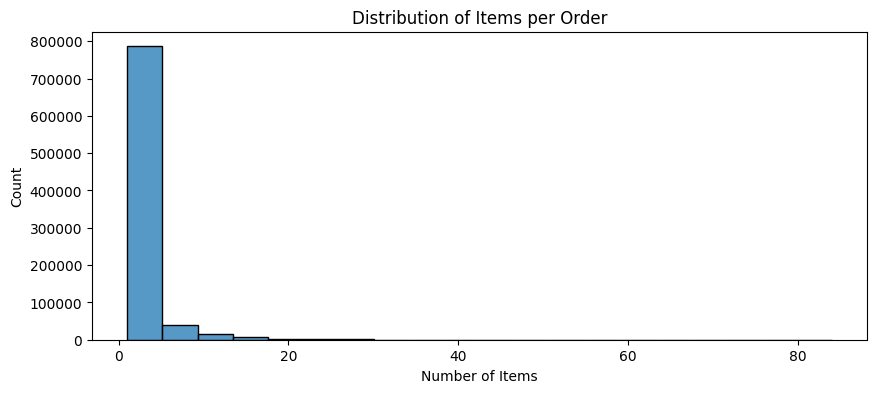

In [60]:
# Number of products per booking
items_per_booking = transactions.groupby('booking_id')['quantity'].sum()
print(f"Items per booking: mean={items_per_booking.mean():.2f}, median={items_per_booking.median():.0f}, max={items_per_booking.max()}")
plt.figure(figsize=(10,4))
sns.histplot(items_per_booking, bins=20)
plt.title('Distribution of Items per Order')
plt.xlabel('Number of Items')
plt.show()

In [61]:
promo_orders = transactions[transactions['is_discounted']].groupby('booking_id')['booking_id'].nunique().count()
total_orders = transactions['booking_id'].nunique()
print(f"Orders with discount: {promo_orders}/{total_orders} ({100*promo_orders/total_orders:.1f}%)")

Orders with discount: 326536/852584 (38.3%)


In [62]:
# Number of orders per customer
orders_per_cust = transactions.groupby('customer_id')['booking_id'].nunique()
print(f"Orders per customer: mean={orders_per_cust.mean():.2f}, median={orders_per_cust.median():.0f}, max={orders_per_cust.max()}")

Orders per customer: mean=16.81, median=6, max=550


In [63]:
# Very high order value
high_value = transactions[transactions['total_amount'] > 10_000_000]
print(f"Orders > 10M: {len(high_value)}")
if len(high_value) > 0:
    print(high_value.head())

Orders > 10M: 6917
                           created_at  customer_id  \
4004 2019-09-03 01:14:52.071343+00:00        93592   
4005 2019-09-03 01:14:52.071343+00:00        93592   
9691 2020-02-08 05:11:20.975075+00:00        80250   
9692 2020-02-08 05:11:20.975075+00:00        80250   
9693 2020-02-08 05:11:20.975075+00:00        80250   

                                booking_id  \
4004  39cc4328-6143-41ac-bafe-660f59a67e37   
4005  39cc4328-6143-41ac-bafe-660f59a67e37   
9691  7883725b-9c49-46f8-a569-3fc778765721   
9692  7883725b-9c49-46f8-a569-3fc778765721   
9693  7883725b-9c49-46f8-a569-3fc778765721   

                                session_id payment_method payment_status  \
4004  42532689-5b7f-4ecd-8d41-98c32e2ee99d        LinkAja        Success   
4005  42532689-5b7f-4ecd-8d41-98c32e2ee99d        LinkAja        Success   
9691  3cf1c195-9c06-4171-9361-abbec7e0ccc4        LinkAja        Success   
9692  3cf1c195-9c06-4171-9361-abbec7e0ccc4        LinkAja        Success   

In [64]:
# Get the top 10 booking IDs by total_amount
top_orders = transactions.groupby('booking_id')['total_amount'].first().nlargest(10)
top_booking_ids = top_orders.index.tolist()

# Filter the transactions DataFrame
top_orders_data = transactions[transactions['booking_id'].isin(top_booking_ids)]

# Show the result, sorted by total_amount descending
top_orders_data = top_orders_data.sort_values('total_amount', ascending=False)
top_orders_data

,created_at,customer_id,booking_id,session_id,payment_method,payment_status,promo_amount,promo_code,shipment_fee,shipment_date_limit,shipment_location_lat,shipment_location_long,total_amount,is_discounted,discount_pct,product_id,quantity,item_price
772681,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,5746,1,281343
772680,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,1608,2,273307
772679,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,13927,23,293553
772699,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,11833,1,112244
772700,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,14433,1,370760
772701,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,58805,1,237552
772702,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,17039,1,500505
772703,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,32925,3,244294
772704,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,6724,2,314580
772705,2020-02-29 18:13:22.812328+00:00,85994,605d6152-6a20-45e5-89b8-ca8b88650f09,df469aed-a6c0-4c12-9abf-c9dbbf7d45d4,Credit Card,Success,0,NO_PROMO,10000,2020-03-06 17:57:01.689740+00:00,-9.334376,124.759026,23504487,False,0.000000,44840,1,617315


No Obvious Anomalies, it looks like bulk purchases

In [65]:
transactions.to_parquet("../data/interim/transactions_clean.parquet", index=False)